# 01 · Data loading, validation and exploratory analysis

> **All data in this notebook are synthetic** (fictional Indian retail brokerage, 10,000 users, Nov 2025 - Oct 2026, INR, snapshot 2026-10-31). No real company data are used.

**Purpose:** load the Phase 2 cleaned tables, re-run integrity checks, and explore the data before any business metric is computed.

**Source-of-truth rule:** the *Users* table drives funnel / CAC / conversion; *Monthly_Activity* drives MAU / retention / repeat trading. They disagree for many users (shown below), so mixed-source results are indicative only.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from fintech_analytics import config as C, loading, cleaning, eda, funnel, campaign, cohort, segmentation, support, kpi_report
%matplotlib inline
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
d = loading.load_all(); users, act, tix, camp = d['users'], d['activity'], d['tickets'], d['campaigns']
print(f'users={len(users):,}  monthly rows={len(act):,}  tickets={len(tix):,}  campaigns={len(camp)}  (ALL DATA SYNTHETIC)')

users=10,000  monthly rows=64,645  tickets=7,614  campaigns=10  (ALL DATA SYNTHETIC)


## 1 · Integrity checks on the cleaned tables
Every run re-validates keys, foreign keys, date bounds, nested funnel flags and value ranges. The raw file is never modified.

In [2]:
chk = cleaning.validate_cleaned(d)
print(f'{int(chk.passed.sum())}/{len(chk)} checks passed')
chk

18/18 checks passed


,check,passed,detail
0,users.user_id unique,True,10000 rows
1,"users row count = 10,000",True,10000
2,campaign ids in users exist in campaigns,True,
3,"activity (user_id, month) unique",True,64645 rows
4,activity users exist in users,True,
5,tickets.ticket_id unique,True,7614 rows
6,ticket users exist in users,True,
7,no registration after snapshot,True,
8,kyc_date_asof not after snapshot,True,
9,bank_date_asof not after snapshot,True,


## 2 · Column profile (missing values, ranges)
Missing values in date/duration columns are *structural* (a user who never reached a stage has no stage date) - they are not data errors.

In [3]:
prof = pd.concat([eda.profile(users,'users'), eda.profile(act,'monthly_activity'), eda.profile(tix,'support_tickets'), eda.profile(camp,'campaigns')])
prof[prof.missing_pct>0].sort_values('missing_pct', ascending=False).head(15)

,column,table,dtype,missing_pct,unique,min,max
14,avg_trade_value_inr,monthly_activity,float64,69.5,19508,178.68,115912.38
44,days_reg_to_trade,users,float64,64.6,40,4.00,43.00
32,trade_date_asof,users,datetime64[us],64.6,351,NaN,NaN
43,days_deposit_to_trade,users,float64,64.6,11,1.00,11.00
18,first_trade_date,users,str,61.8,387,NaN,NaN
19,first_trade_segment,users,str,61.8,4,NaN,NaN
34,first_deposit_amount_asof_inr,users,float64,54.9,4502,500.00,135951.24
30,deposit_date_asof,users,datetime64[us],54.9,357,NaN,NaN
42,days_bank_to_deposit,users,float64,54.9,14,1.00,14.00
15,first_deposit_date,users,str,52.1,386,NaN,NaN


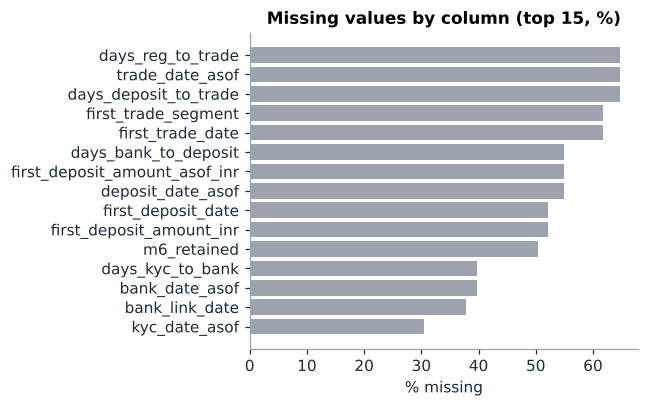

In [4]:
eda.plot_missingness(users); plt.tight_layout(); plt.show()

## 3 · Acquisition shape

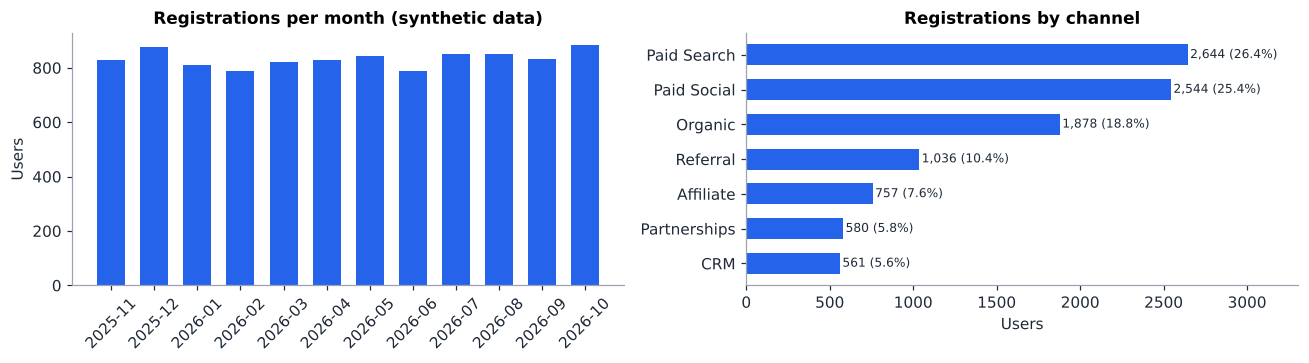

,acquisition_channel,registrations,share_pct
3,Paid Search,2644,26.4
4,Paid Social,2544,25.4
2,Organic,1878,18.8
6,Referral,1036,10.4
0,Affiliate,757,7.6
5,Partnerships,580,5.8
1,CRM,561,5.6


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4)); eda.plot_registrations(users, ax[0]); eda.plot_channel_mix(users, ax[1]); plt.tight_layout(); plt.show()
eda.channel_mix(users)

Registrations are fairly flat across months (no strong seasonality), and Paid Search + Paid Social bring about half of all users; Organic is ~19%.

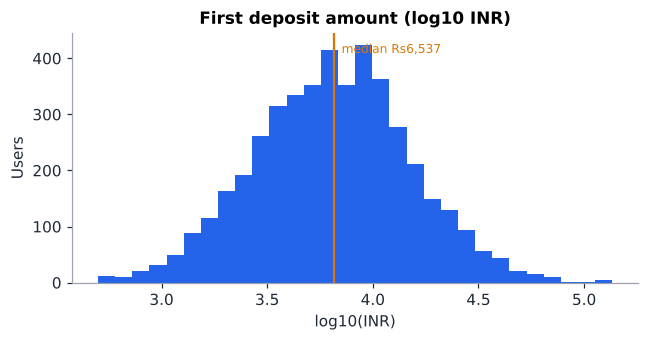

count      4512.0
mean       9260.0
std        9619.0
min         500.0
25%        3618.0
50%        6537.0
75%       11352.0
max      135951.0
Name: first_deposit_amount_asof_inr, dtype: float64

In [6]:
eda.plot_deposit_hist(users); plt.tight_layout(); plt.show()
users.first_deposit_amount_asof_inr.describe().round(0)

## 4 · Known data property: the two sources disagree
The table below crosses *'ever traded' per the Users table* with *'ever traded' per Monthly_Activity*. The large off-diagonal is a documented property of the synthetic data (Phase 2 flags `flag_*_conflict`). That is why each metric family is tied to one source.

In [7]:
cleaning.source_conflict_summary(users, act)

traded_monthly,monthly: not traded,monthly: traded
trade_asof,,
users: not traded,2563,3901
users: traded,59,3477
